<div class="alert alert-warning">

### (Practical) Data Visualization · WS 2026/27
## Homework: Tidy Data, Marks & Channels
</div>

**Due:** November 17, 2026, 18:00 

**Instructions:** Please complete this notebook (e.g. using JupyterHub) and submit it via OLAT by the deadline. Write answers in the designated Markdown cells, and complete the code cells marked `TODO`.

**Important:**
- Before you submit, check that all notebook cells run from top to bottom without errors (clicking "Restart and run all cells" works)
- Please do not delete cells or add new cells.
- Download and submit the notebook file (.ipynb) into OLAT, not a PDF or another format.

---

In this homework you will inspect a public German dataset on renewable energy and visualize some of the data.

### Dataset: Renewable electricity in Germany

In this homework, you will inspect a public German dataset on renewable energy and visualize some of the data. It uses selected figures from **Statistikportal**, published by the statistical offices of the German federal states (*Statistische Ämter des Bundes und der Länder*). It covers the **16 Bundesländer and Germany as a whole** for **1990, 2000, 2010, 2020, 2023, and 2024**.

The two measurements (both in **percent**) are:

- **`generation_share_percent`**: share of renewable sources in gross electricity **generation**.
- **`consumption_share_percent`**: electricity from renewable sources as a percentage of gross electricity **consumption**.

These measure **different denominators**: a state's consumption-related percentage may exceed 100% if more renewable electricity is generated than is consumed there. Values for **2024 are provisional**.

The provided `germany_renewables_untidy.csv` is an **adapted classroom extract** combining two public tables. The numerical values are unchanged; unavailable values in the original tables are represented by **empty cells** in the CSV. The original tables use wide year columns as well, but we have deliberately arranged the indicators in rows to create an additional reshaping challenge.

**Original public tables (source, August 2026):**
- [Renewable share of electricity generation](https://www.statistikportal.de/de/nachhaltigkeit/ergebnisse/ziel-7-bezahlbare-und-saubere-energie/anteil-erneuerbarer-energien-der)
- [Renewable electricity relative to gross electricity consumption](https://www.statistikportal.de/de/nachhaltigkeit/ergebnisse/ziel-7-bezahlbare-und-saubere-energie/anteil-des-stroms-aus-erneuerbaren)

### Before you start

1. Open [RPTU JupyterHub](https://rptu.de/jupyterhub) or your own installation with a **Python 3** kernel or use a local Jupyter installation.
2. Download  **`germany_renewables_untidy.csv`** from OLAT. If using JupyterHub, upload the CSV into the **same folder as the notebook**.
3. Run the notebook from top to bottom using **Shift + Enter**; do not skip the setup cells.
4. If you encounter `ModuleNotFoundError`, run `%pip install pandas seaborn matplotlib` in a separate code cell and restart/rerun as needed. For file errors, verify the working directory and filename.
5. You **may use AI tools for explanations, prototyping or debugging**, but check the outputs yourself. Your notebook should contain your own reasoning, runnable code, and both plots – not merely screenshots.

**Documentation:** [Pandas user guide](https://pandas.pydata.org/docs/user_guide/index.html), [Seaborn tutorials](https://seaborn.pydata.org/tutorial.html), [Jupyter basics](https://jupyter-notebook.readthedocs.io/en/stable/notebook.html).

---

<div class="alert alert-info">
<h3>Task 1 — Data Wrangling</h3>
</div>

Let's load the CSV as a pandas DataFrame named `raw` and display the first 20 rows.

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

raw = pd.read_csv(r"D:\Winter Semester\Data Visualization\germany_renewables_untidy.csv")
raw.head(20)

,region,measure,1990,2000,2010,2020,2023,2024
0,Baden-Württemberg,generation_share_percent,8.5,12.5,17.2,40.6,52.5,58.9
1,Bayern,generation_share_percent,15.4,18.6,25.9,51.9,70.4,NaN
2,Berlin,generation_share_percent,NaN,NaN,4.0,6.9,5.3,6.4
3,Brandenburg,generation_share_percent,NaN,NaN,19.9,42.6,45.1,49.5
4,Bremen,generation_share_percent,1.2,1.5,5.4,18.6,NaN,NaN
5,Hamburg,generation_share_percent,NaN,NaN,12.9,12.6,23.5,27.2
6,Hessen,generation_share_percent,1.1,3.1,10.7,54.7,57.8,56.8
7,Mecklenburg-Vorpommern,generation_share_percent,NaN,NaN,46.0,85.9,NaN,NaN
8,Niedersachsen,generation_share_percent,NaN,NaN,22.1,54.3,73.4,75.7
9,Nordrhein-Westfalen,generation_share_percent,0.3,1.1,6.1,19.2,24.2,NaN


<div class="alert alert-success">
    
**Task 1.1:** Explain why this is **not a tidy table**. What does each row represent in its current form? Which attributes are stored in column names? Why should a missing entry **not automatically be treated as 0%**?

</div>

**Your answer (3–5 sentences):**  
The table is not tidy because one observation (a region in a given year) is spread over several cells and rows, and the variable *year* is stored in the column names (`1990`, `2000`, …, `2024`) instead of in its own column. In its current form, each row represents one **region × measure** combination with all its yearly values, so the two variables `generation_share_percent` and `consumption_share_percent` appear as *values* of the `measure` column instead of as separate columns. In a tidy table every variable (region, year, generation share, consumption share) would be a column and every (region, year) observation one row. A missing entry must not be treated as 0% because it means the value was **not available/not published** in the original statistics (e.g. no figures for several states in 1990/2000), not that no renewable electricity was produced; setting it to 0 would invent data and create false drops in the charts and wrong averages.

<div class="alert alert-success">
    
**Task 1.2:** Next, create a tidy dataframe with one row per `(region, year)` and `generation_share_percent`, `consumption_share_percent` as dependent variables. Before writing code, describe which columns you need to **melt**, and which columns should be **cast**.  
<div>

**Your answer:**  
- **Melt:** the six year columns `1990, 2000, 2010, 2020, 2023, 2024` are melted into two columns, `year` (from the column names) and `percent` (from the cell values). The identifying columns `region` and `measure` stay as they are (`id_vars`).  
- **Cast (pivot):** the `measure` column is cast, i.e. its two values `generation_share_percent` and `consumption_share_percent` become two separate columns, filled with the values from `percent`. The index of the cast is `(region, year)`, so the result has one row per region and year.

<div class="alert alert-success">
    
**Task 1.3:** Use [`pandas.DataFrame.melt`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.melt.html) **once** to bring all years into a single `year` column and their values into a `percent` column. Keep the identifying attributes. Name the result `melted` and display its first few rows.

*Hint:* The argument `id_vars` to `melt` identifies columns that remain unchanged; `var_name` and `value_name` specify the names of the new columns.
</div>

In [9]:
# Task 1.3: one melt operation
melted = raw.melt(
    id_vars=["region", "measure"],   # identifying attributes stay as columns
    var_name="year",                 # former column names 1990 ... 2024
    value_name="percent",            # former cell values
)
melted["year"] = melted["year"].astype(int)   # year as a number, not a string

display(melted.head())

,region,measure,year,percent
0,Baden-Württemberg,generation_share_percent,1990,8.5
1,Bayern,generation_share_percent,1990,15.4
2,Berlin,generation_share_percent,1990,NaN
3,Brandenburg,generation_share_percent,1990,NaN
4,Bremen,generation_share_percent,1990,1.2


<div class="alert alert-success">
    
**Task 1.4:** Use [`pandas.DataFrame.pivot`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pivot.html) **once** to create a tidy DataFrame named `tidy`. One row should represent a region in a particular year; the two measures should have separate columns.

*Hint:* `index` supplies the identifying attributes, `columns` specifies what becomes the new column names, and `values` supplies the cell values. You may need `.reset_index()` to turn index levels back into columns.
</div>

In [10]:
# Task 1.4: one pivot operation
tidy = (
    melted.pivot(index=["region", "year"], columns="measure", values="percent")
    .reset_index()
)
tidy.columns.name = None   # remove the leftover "measure" label from the column index

display(tidy.head())

,region,year,consumption_share_percent,generation_share_percent
0,Baden-Württemberg,1990,8.1,8.5
1,Baden-Württemberg,2000,11.6,12.5
2,Baden-Württemberg,2010,13.8,17.2
3,Baden-Württemberg,2020,27.4,40.6
4,Baden-Württemberg,2023,31.3,52.5


<div class="alert alert-success">
    
**Task 1.5** There should be **102 (region, year) combinations** (17 regions × 6 years), whether or not some measurement values are missing. Check the row count, duplicate region/year combinations, numeric column types, and remaining missing values.

</div>

In [11]:
# Task 1.5: check the tidy data structure
print("Shape:", tidy.shape)                       # expected (102, 4)
print("Rows == 17 regions x 6 years:", len(tidy) == 17 * 6)
print("Regions:", tidy["region"].nunique(), "| Years:", sorted(tidy["year"].unique()))
print("Duplicate (region, year) pairs:", tidy.duplicated(subset=["region", "year"]).sum())
print("\nColumn types:")
print(tidy.dtypes)
print("\nMissing values per column:")
print(tidy.isna().sum())

# Which (region, year) combinations have no value for a measure?
missing_rows = tidy[tidy[["generation_share_percent", "consumption_share_percent"]].isna().any(axis=1)]
display(missing_rows)

Shape: (102, 4)
Rows == 17 regions x 6 years: True
Regions: 17 | Years: [np.int64(1990), np.int64(2000), np.int64(2010), np.int64(2020), np.int64(2023), np.int64(2024)]
Duplicate (region, year) pairs: 0

Column types:
region                           str
year                           int64
consumption_share_percent    float64
generation_share_percent     float64
dtype: object

Missing values per column:
region                        0
year                          0
consumption_share_percent    25
generation_share_percent     25
dtype: int64


,region,year,consumption_share_percent,generation_share_percent
11,Bayern,2024,NaN,NaN
12,Berlin,1990,NaN,NaN
13,Berlin,2000,NaN,NaN
18,Brandenburg,1990,NaN,NaN
19,Brandenburg,2000,NaN,NaN
28,Bremen,2023,NaN,NaN
29,Bremen,2024,NaN,NaN
36,Hamburg,1990,NaN,NaN
37,Hamburg,2000,NaN,NaN
48,Mecklenburg-Vorpommern,1990,NaN,NaN


---

<div class="alert alert-info">
    
## Task 2 — Implement a Visualization
</div>

Your goal here is to implement a visualization in support of the following analytical task: How did the share of renewables in electricity generation change over time in Rheinland-Pfalz, Sachsn*, Schleswig-Holstein, and Germany as a whole?

<div class="alert alert-success">

**Task 2.1:**
Create a line chart from `tidy` using [`seaborn.lineplot`](https://seaborn.pydata.org/generated/seaborn.lineplot.html).

Use these marks and channels:

| Mark / channel | Data mapping |
|---|---|
| Line marks | Each line connects observations of the **same region** over time |
| Horizontal position | `year` (quantitative/temporal) |
| Vertical position | `generation_share_percent` (quantitative) |
| Color hue | `region` (categorical) |

Show a marker at every available observation. Label both axes with units and provide a legend. **Do not replace missing data with zero.** Year intervals are unequal, so make sure the year is numeric rather than treated as an equally spaced category.

Documentation: [Seaborn lineplot](https://seaborn.pydata.org/generated/seaborn.lineplot.html)

</div>

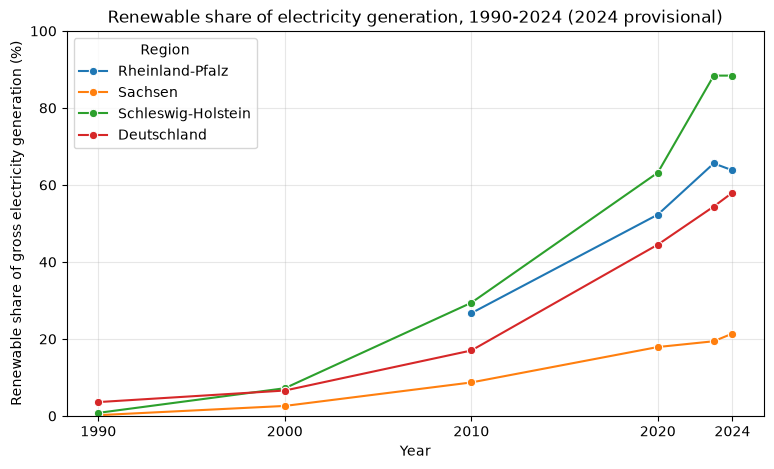

In [12]:
# filter out the desired regions
selected_regions = [
    "Rheinland-Pfalz", "Sachsen", "Schleswig-Holstein", "Deutschland"
]
selected = tidy[tidy["region"].isin(selected_regions)]

fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(
    data=selected.dropna(subset=["generation_share_percent"]),  # missing years are left out, never set to 0
    x="year",                          # numeric year -> real spacing between 1990, 2000, ..., 2023, 2024
    y="generation_share_percent",
    hue="region",
    hue_order=selected_regions,
    marker="o",                        # a marker at every available observation
    ax=ax,
)
ax.set_xticks([1990, 2000, 2010, 2020, 2024])   # 2023 sits just left of 2024 (labels would overlap)
ax.set_xlabel("Year")
ax.set_ylabel("Renewable share of gross electricity generation (%)")
ax.set_title("Renewable share of electricity generation, 1990-2024 (2024 provisional)")
ax.set_ylim(0, 100)
ax.legend(title="Region")
ax.grid(alpha=0.3)

plt.show()

<div class="alert alert-success">

**2.2** Describe one notable change visible in your plot. What do missing data points imply about which comparisons are possible?
</div>

**Your answer (2–3 sentences):**  
Schleswig-Holstein shows the strongest change: its renewable share of generation rose from 0.8% in 1990 to 88.4% in 2023/2024 and has been above the German average since 2010, while Sachsen grew only to 21.4% and fell further and further behind Germany as a whole (58.0% in 2024). Rheinland-Pfalz has no data for 1990 and 2000, so its line only starts in 2010; for the early period we can therefore compare only Sachsen, Schleswig-Holstein and Germany, and statements about Rheinland-Pfalz's long-term growth since 1990 are not possible (the missing years must not be read as 0%). Also, 2024 values are provisional, so the small dip in Rheinland-Pfalz (65.6% → 63.8%) should be interpreted with caution.

---

<div class="alert alert-info">
    
## Task 3 — Design alternative visualizations
</div>

<div class="alert alert-success">
    
**Task 3.1 — Design.** Address the **same analytical task and the same four regions** as in Task 3, but propose a **different mark type or a different data-to-channel mapping**. Changing only the colors or line thickness does not count.

State:
- Your proposed **mark type** and **channel → attribute** mappings.
- Why these encodings might make a particular comparison easier (or harder) than the prescribed line chart.
- How you will handle the missing observations without making them appear to be zeros.
</div>

**Your answer (4–6 sentences):**  
I propose a **heatmap**: the mark is an **area mark** (one rectangle per region and year), with **vertical position (row) → `region`**, **horizontal position (column) → `year`** (ordered, but as equally sized categories), and **colour luminance/saturation → `generation_share_percent`** (sequential light-to-dark green scale, 0–100%); the exact value is also written into each cell as a text label. This makes it easy to read a single region/year value and to compare all regions within one year by looking down a column (e.g. the gap between Schleswig-Holstein and Sachsen in 2023). It is harder, however, to judge the *rate* of change, because colour luminance is perceived much less accurately than position on a common scale and the columns hide the unequal time intervals (10 years vs. 1 year between columns). Missing observations (Rheinland-Pfalz 1990 and 2000) are left as **NaN**, drawn as grey cells labelled "no data", which lies outside the green colour scale, so they cannot be confused with 0%.

<div class="alert alert-success">

**Task 3.2:** **Implement.** Create your alternative chart using **Seaborn**. Keep the data and regions unchanged.

Documentation: [Seaborn examples](https://seaborn.pydata.org/examples/index.html), [barplot](https://seaborn.pydata.org/generated/seaborn.barplot.html), [scatterplot](https://seaborn.pydata.org/generated/seaborn.scatterplot.html), [heatmap](https://seaborn.pydata.org/generated/seaborn.heatmap.html).
</div>

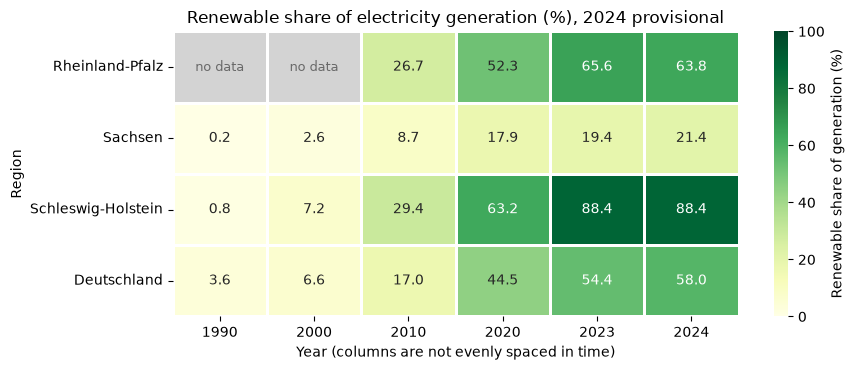

In [13]:
# Task 3.2: alternative design - heatmap (region x year, colour = generation share)
heat = (
    selected.pivot(index="region", columns="year", values="generation_share_percent")
    .reindex(selected_regions)          # same region order as in the line chart
)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.set_facecolor("lightgrey")          # cells without data stay grey (NaN is not drawn as a colour)
sns.heatmap(
    heat,
    annot=True, fmt=".1f",             # exact value written in every available cell
    cmap="YlGn", vmin=0, vmax=100,     # 0 % = light, 100 % = dark green
    linewidths=1, linecolor="white",
    cbar_kws={"label": "Renewable share of generation (%)"},
    ax=ax,
)
# mark the missing cells explicitly so they cannot be read as 0 %
for i, region in enumerate(heat.index):
    for j, year in enumerate(heat.columns):
        if pd.isna(heat.loc[region, year]):
            ax.text(j + 0.5, i + 0.5, "no data", ha="center", va="center", color="dimgray", fontsize=9)

ax.set_xlabel("Year (columns are not evenly spaced in time)")
ax.set_ylabel("Region")
ax.set_title("Renewable share of electricity generation (%), 2024 provisional")
plt.tight_layout()
plt.show()

<div class="alert alert-success">
    
**Task 3.3:** **Compare.** Which of your two designs better supports the analytical task? Explain with reference to **marks, channels, and perceptual effectiveness**.
</div>

**Your answer (2–4 sentences):**  
The **line chart** better supports the analytical task "how did the share change over time", because it encodes the share with **vertical position on a common aligned scale**, the most accurate channel for quantitative values, and uses **numeric horizontal position** for time, so slopes show the true speed of change across the unequal year intervals; the line marks also connect each region's observations so trends are visible at a glance. The heatmap encodes the share with **colour luminance**, which is perceptually much less precise, and places years at equal distances, so trends are distorted and small differences (e.g. 63.8 vs 65.6) are hard to see without reading the text labels. The heatmap is mainly useful for looking up exact values and spotting missing data, which it shows very clearly.

---